# GCSI Quickstart

## Global Commodity Sentiment Indices: first call, first chart

This notebook gets you from an API key to a chart of Brent Crude sentiment in a few minutes. It:

1. Authenticates and pulls a week of the **hourly index** for one commodity (`BZ_COM`)
2. Shows the schema and what each field means
3. Turns hourly bars into a daily series for each **horizon** (`short_term`, `medium_term`, `long_term`)
4. Lists the topics that carried the most news this week

| Key fact | Value |
|---|---|
| Granularity | One row per ticker × topic × index type × horizon × hour |
| `processed_at` | **End** of the hour (UTC), binned by when Permutable processed the headlines (when they became available) |
| Sign | Positive = bullish for the commodity price |
| Missing hours | Omitted, not zero-filled |

> **Disclaimer:** This notebook is provided for informational and research purposes only. Nothing here constitutes financial advice or a recommendation to buy, sell, or hold any asset. Sentiment scores are model outputs describing how news was judged at publication; they are not price forecasts.

In [ ]:
%pip install requests pandas numpy matplotlib seaborn

## Step 1: Configuration

The API client, storage, metrics and chart helpers live in [`../utils`](../utils/), shared by every notebook in this folder. Open them to see how each step works.

In [2]:
import sys
from datetime import datetime, timedelta, timezone
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path('..').resolve()))  # notebooks/, for the shared utils package
from utils import charts, metrics
from utils.api import GcsiClient, to_index_frame

TICKER = 'BZ_COM'
INDEX_TYPE = 'COMBINED'      # EXPLICIT | RELATED_ENTITY | MACROECONOMIC | COMBINED
SENTIMENT_TYPES = ['short_term', 'medium_term', 'long_term']
LOOKBACK_DAYS = 7

client = GcsiClient()        # API_KEY from the environment or a .env file, otherwise a prompt
TICKER_NAME = charts.ticker_label(TICKER)
print(f'Ticker: {TICKER} | index type: {INDEX_TYPE} | last {LOOKBACK_DAYS} days')

Ticker: BZ_COM | index type: COMBINED | last 7 days


## Step 2: Load a week of data

One historical request per horizon.

In [3]:
start = (datetime.now(timezone.utc) - timedelta(days=LOOKBACK_DAYS)).date()
records = []
for sentiment_type in SENTIMENT_TYPES:
    rows = client.index_history(TICKER, start, index_type=INDEX_TYPE, sentiment_type=sentiment_type)
    print(f'{sentiment_type:>12}: {len(rows):,} hourly rows')
    records.extend(rows)
hourly = to_index_frame(records)

if hourly.empty:
    raise SystemExit('No rows returned: check the ticker, your licence, and the endpoint block.')

print(f"{len(hourly):,} rows | {hourly['topic_name'].nunique()} topics | "
      f"{hourly['processed_at'].min():%Y-%m-%d %H:%M} → {hourly['processed_at'].max():%Y-%m-%d %H:%M} UTC")

  short_term: 2,646 hourly rows


 medium_term: 2,646 hourly rows


   long_term: 2,646 hourly rows
7,938 rows | 24 topics | 2026-11-03 00:00 → 2026-11-10 15:00 UTC


## Step 3: Inspect the schema

| Field | Meaning |
|---|---|
| `headline_count` | Distinct articles in the hour for this topic |
| `sentiment_sum` | Sum of scores (−1 to +1 each) |
| `sentiment_std` | Sample standard deviation within the hour (0 if fewer than two headlines) |

The main derived value is `sentiment_avg = sentiment_sum / headline_count`, in [−1, +1].

In [4]:
columns = ['processed_at', 'topic_name', 'sentiment_type', 'headline_count', 'sentiment_sum', 'sentiment_std']
sample = hourly[columns].sort_values('processed_at').tail(8).copy()
sample['sentiment_avg'] = sample['sentiment_sum'] / sample['headline_count']
display(sample)

,processed_at,topic_name,sentiment_type,headline_count,sentiment_sum,sentiment_std,sentiment_avg
2635,2026-11-10 15:00:00+00:00,Energy::Supply::Other,short_term,3,-1.270,0.077,-0.423333
2636,2026-11-10 15:00:00+00:00,Energy::Macro::Global Trade & Sanctions,short_term,14,1.450,0.140,0.103571
2637,2026-11-10 15:00:00+00:00,Energy::Supply::Infrastructure & Logistics,short_term,19,3.642,0.103,0.191684
2638,2026-11-10 15:00:00+00:00,Energy::Supply::Disruptions,short_term,16,4.151,0.138,0.259437
2639,2026-11-10 15:00:00+00:00,Energy::Macro::Conflict,short_term,67,12.452,0.224,0.185851
2640,2026-11-10 15:00:00+00:00,Energy::Market::Forecasts,short_term,5,-0.145,0.080,-0.029000
5290,2026-11-10 15:00:00+00:00,Energy::Demand::Industrial & Power,medium_term,1,0.105,0.000,0.105000
7937,2026-11-10 15:00:00+00:00,Energy::Macro::Producer Policy,long_term,1,0.055,0.000,0.055000


## Step 4: Daily sentiment by horizon

Topics are multi-label: one headline can sit in several topics. Adding rows across topics therefore gives a
**topic-weighted** average, and the count is a count of *topic-links*, not articles. That is the right input
for an overall reading, but label it accurately.

Hourly bars are grouped by the UTC day the headlines were processed. A bar stamped 00:00 covers the last hour
of the previous day.

`metrics.pool` adds hours into days and pools the standard deviation exactly, rather than averaging hourly standard deviations.

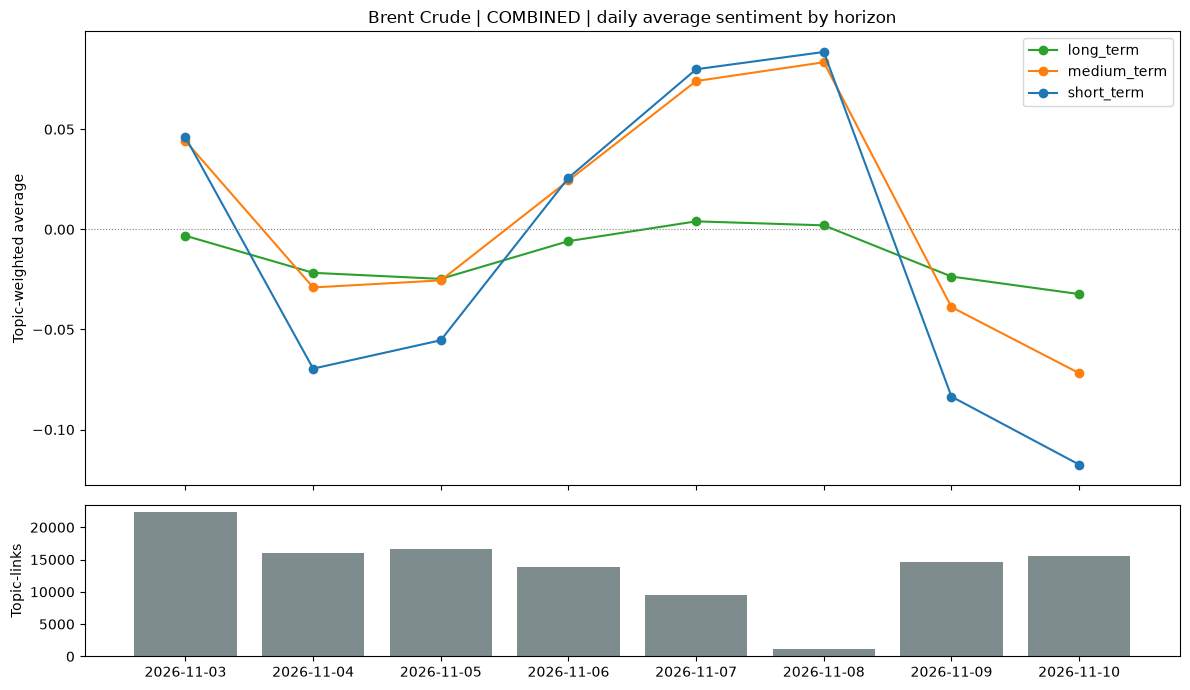

In [5]:
hourly['date'] = metrics.processed_date(hourly['processed_at'])
daily = metrics.pool(hourly, ['date', 'sentiment_type'])
daily = daily[daily['date'] >= pd.Timestamp(start)]  # the first bar covers the last hour of the day before
charts.daily_horizons(daily, f'{TICKER_NAME} | {INDEX_TYPE} | daily average sentiment by horizon')

## Step 5: Which topics carried the news this week?

Short-term horizon, ranked by volume, then the same news grouped by driver (the middle level of the topic label). Averages from a handful of headlines are noisy, so treat small topics with care.

,topic_name,headline_count,sentiment_avg,sentiment_std
9,Energy::Macro::Geopolitics,30448,-0.060,0.214
7,Energy::Macro::Conflict,27336,0.169,0.165
17,Energy::Market::Prices,27207,-0.238,0.380
8,Energy::Macro::Economy & Central Banks,5697,-0.013,0.160
20,Energy::Supply::Infrastructure & Logistics,4458,0.109,0.174
10,Energy::Macro::Global Trade & Sanctions,2984,0.043,0.129
18,Energy::Supply::Disruptions,2418,0.194,0.110
3,Energy::Demand::Industrial & Power,1596,0.057,0.184
5,Energy::Demand::Transportation,1473,-0.122,0.144
14,Energy::Market::Forecasts,1345,-0.067,0.208


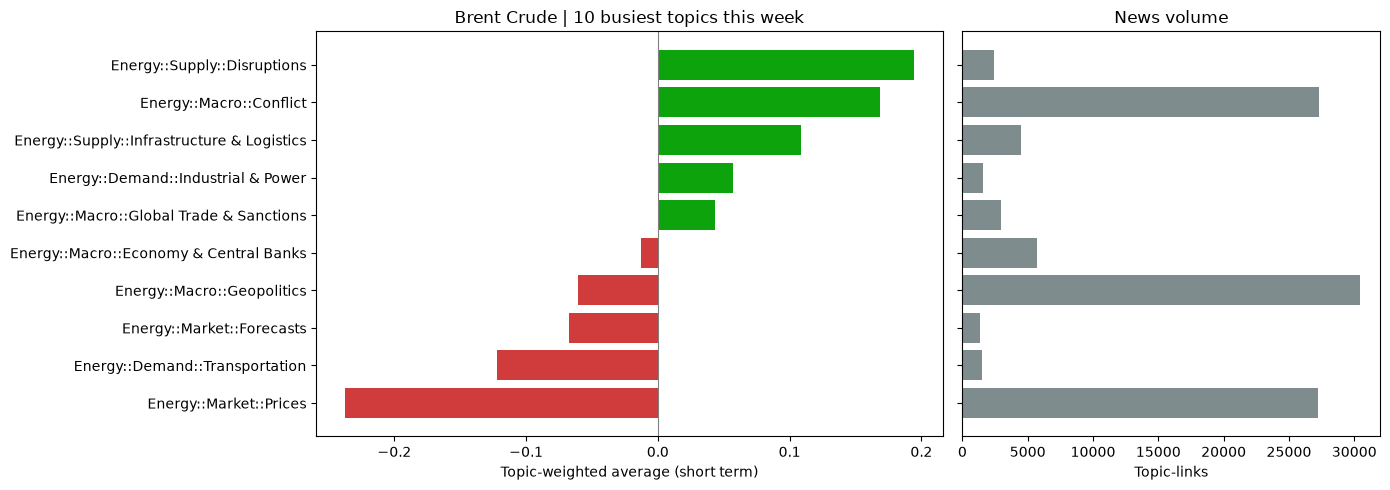

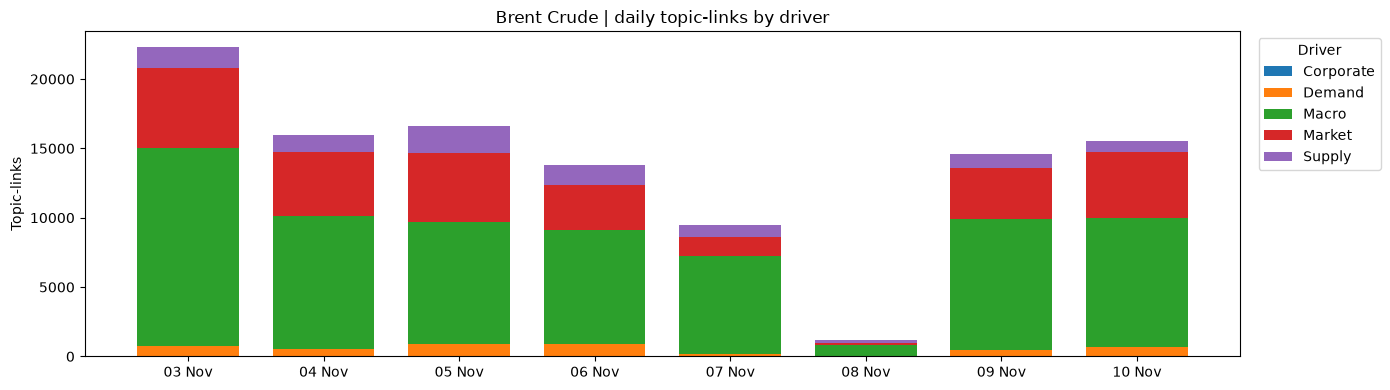

In [6]:
short = hourly[hourly['sentiment_type'] == 'short_term']
by_topic = metrics.pool(short, ['topic_name']).sort_values('headline_count', ascending=False)
display(by_topic[['topic_name', 'headline_count', 'sentiment_avg', 'sentiment_std']].head(10).round(3))
charts.busiest_topics(by_topic, f'{TICKER_NAME} | 10 busiest topics this week')

# Volume by L1 driver (Sector::Driver::Topic), day by day
by_driver = (short.assign(driver=metrics.driver(short['topic_name']))
             .groupby(['date', 'driver'])['headline_count'].sum().unstack(fill_value=0))
charts.stacked_daily_bars(by_driver[by_driver.index >= pd.Timestamp(start)],
                          f'{TICKER_NAME} | daily topic-links by driver', legend_title='Driver')

## Next steps

| Notebook | Use it to |
|---|---|
| `gcsi_infrastructure_watchlist.ipynb` | Follow news about named refineries, pipelines and storage sites |
| `../live/gcsi_index_polling.ipynb` | Poll the hourly index continuously and build an indicator |
| `../live/gcsi_headline_polling.ipynb` | Work with individual headlines and match types |